# One-dimensional Bayes localisation

A discrete Bayes (histogram) filter implemented with NumPy, with simulation experiments on localisation accuracy and calibration. The method follows Thrun, Burgard and Fox (2005), *Probabilistic Robotics*, chapter 4.

1. Measurement update on three cells, checked against a hand calculation
2. Measurement and motion updates on a loop of 10 cells
3. Range-sensor localisation in a 20 m corridor
4. Calibration of the 90% credible region
5. Limitations

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

Path("figures").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def entropy(p):
    # Shannon entropy in nats; the maximum for N cells is ln(N).
    p = p[p > 0]
    return float(-(p * np.log(p)).sum())

## 1. Measurement update

A robot occupies one of three cells (wall, door, wall) with a uniform prior of 1/3. The door sensor is correct with probability 0.8. After a "door" reading, Bayes' rule gives P(cell | reading) proportional to P(reading | cell) P(cell).

The likelihoods are 0.2, 0.8 and 0.2, so the unnormalised posterior is (0.2, 0.8, 0.2)/3, which sums to 1.2/3. The normalised posterior is (1/6, 2/3, 1/6). The code below reproduces this result.

In [2]:
world3 = np.array(["wall", "door", "wall"])
belief3 = np.full(3, 1 / 3)

def sense_discrete(belief, world, reading, p_correct):
    # Likelihood of the reading in each cell: p_correct if the cell matches, else 1 - p_correct.
    likelihood = np.where(world == reading, p_correct, 1 - p_correct)
    posterior = likelihood * belief          # Bayes' rule, unnormalised
    return posterior / posterior.sum()       # normalise so the belief sums to 1

after_one = sense_discrete(belief3, world3, "door", 0.8)
print("after one 'door' reading :", np.round(after_one, 4))
assert np.allclose(after_one, [1 / 6, 2 / 3, 1 / 6])      # matches the hand calculation

after_two = sense_discrete(after_one, world3, "door", 0.8)
print("after a second reading   :", np.round(after_two, 4))
# By hand: [0.2/6, 0.8*2/3, 0.2/6] = [0.0333, 0.5333, 0.0333]; they sum to 0.6, so divide: [0.0556, 0.8889, 0.0556]
assert np.allclose(after_two, [1 / 18, 8 / 9, 1 / 18])

after one 'door' reading : [0.1667 0.6667 0.1667]
after a second reading   : [0.0556 0.8889 0.0556]


Two consistent readings raise the belief in the middle cell from 1/3 to 2/3 to 8/9.

## 2. Measurement and motion updates on a loop

The world is a loop of 10 cells containing doors (D) and walls (W). A command to move one cell succeeds with probability 0.8, leaves the robot in place with probability 0.1 and moves it two cells with probability 0.1. Under the Markov assumption, the motion update is a weighted sum of shifted copies of the belief. The filter alternates a measurement update and a motion update.

one certain cell after a move: [0.  0.  0.  0.1 0.8 0.1 0.  0.  0.  0. ]
true cells: [3, 4, 5, 6, 7, 8, 9, 0, 2, 3, 4, 6, 7, 8, 9, 0, 1, 3, 4, 5]
readings  : ['W', 'W', 'W', 'D', 'W', 'W', 'W', 'W', 'W', 'W', 'D', 'D', 'D', 'W', 'W', 'W', 'D', 'W', 'D', 'W']


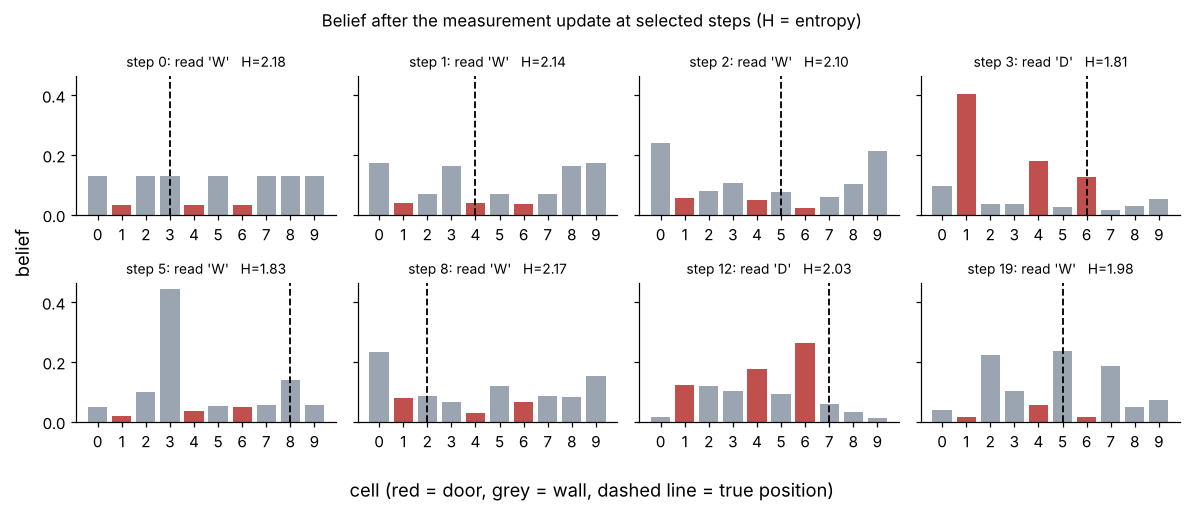

maximum entropy (uniform belief): 2.30


best guess equals the true cell at steps 0, 3, 6, 10, 19: [0.12 0.34 0.34 0.37 0.35] (chance = 0.10)


In [3]:
world10 = np.array(list("WDWWDWDWWW"))       # W = wall, D = door; doors at cells 1, 4 and 6
N10 = len(world10)

def move_discrete(belief, p_exact=0.8, p_under=0.1, p_over=0.1, step=1):
    # np.roll shifts the belief by a number of cells (wrapping around the loop)
    return (p_exact * np.roll(belief, step)
            + p_under * np.roll(belief, step - 1)
            + p_over * np.roll(belief, step + 1))

# Sanity checks: a move conserves probability, and blurs a certain belief into three cells
spike = np.zeros(N10); spike[3] = 1
moved = move_discrete(spike)
assert np.isclose(moved.sum(), 1)
print("one certain cell after a move:", np.round(moved, 2))

def simulate_discrete(rng, T=20, start=3, p_sense=0.8):
    # Generate what the robot actually does and reads. The filter below only sees the readings.
    pos, truth, readings = start, [], []
    for _ in range(T):
        correct = str(world10[pos])
        wrong = "W" if correct == "D" else "D"
        readings.append(correct if rng.random() < p_sense else wrong)
        truth.append(int(pos))
        pos = int((pos + rng.choice([1, 0, 2], p=[0.8, 0.1, 0.1])) % N10)
    return truth, readings

rng = np.random.default_rng(3)
truth10, readings10 = simulate_discrete(rng)
print("true cells:", truth10)
print("readings  :", readings10)

belief = np.full(N10, 1 / N10)
beliefs10 = []
for z in readings10:
    belief = sense_discrete(belief, world10, z, 0.8)
    beliefs10.append(belief.copy())
    belief = move_discrete(belief)

show = [0, 1, 2, 3, 5, 8, 12, 19]                    # steps to draw
fig, axes = plt.subplots(2, 4, figsize=(11, 4.6), sharey=True)
for t, ax in zip(show, axes.ravel()):
    b = beliefs10[t]
    colours = ["#c0504d" if world10[i] == "D" else "#9aa5b1" for i in range(N10)]
    ax.bar(range(N10), b, color=colours)
    ax.axvline(truth10[t], color="black", lw=1.2, ls="--")
    ax.set_title(f"step {t}: read '{readings10[t]}'   H={entropy(b):.2f}", fontsize=9)
    ax.set_xticks(range(N10))
fig.supxlabel("cell (red = door, grey = wall, dashed line = true position)")
fig.supylabel("belief")
fig.suptitle("Belief after the measurement update at selected steps (H = entropy)", fontsize=11)
fig.tight_layout()
fig.savefig("figures/discrete_filter.png", dpi=130)
plt.show()
print("maximum entropy (uniform belief): %.2f" % np.log(N10))

# How often is the single most probable cell the true cell? 300 runs, random starting cells.
hits = np.zeros(20)
for s in range(300):
    r = np.random.default_rng(1000 + s)
    tr, rd = simulate_discrete(r, T=20, start=int(r.integers(N10)))
    b = np.full(N10, 1 / N10)
    for t, z in enumerate(rd):
        b = sense_discrete(b, world10, z, 0.8)
        hits[t] += (b.argmax() == tr[t])
        b = move_discrete(b)
hits /= 300
print("best guess equals the true cell at steps 0, 3, 6, 10, 19:", np.round(hits[[0, 3, 6, 10, 19]], 2), "(chance = 0.10)")

The belief concentrates around door cells but does not converge to a single cell. Motion noise adds uncertainty at each step, and a door/wall reading is weakly informative because seven of the ten cells are walls. Over 300 runs from random starting cells, the most probable cell was the true cell about one third of the time (35% at step 19; chance level 10%).

## 3. Range-sensor localisation in a corridor

The corridor is 20 m long, discretised into 201 cells of 0.1 m, with five landmarks at known positions. The sensor returns the signed distance to the nearest landmark with Gaussian noise (σ = 0.25 m) and does not identify which landmark was observed. Each command moves the robot 0.5 m with Gaussian error (σ = 0.15 m), and the robot stops at the corridor ends. The prior is uniform.

The initial belief is multimodal. Motion resolves the ambiguity because the landmark spacings differ.

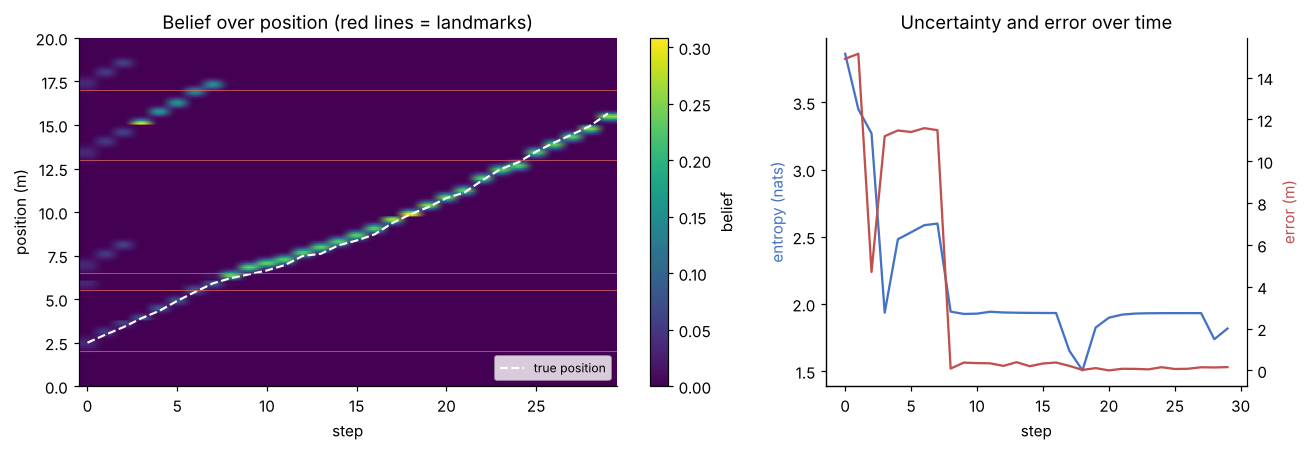

entropy after the first reading: 3.86 nats (uniform belief: 5.30)
first step with >90% of belief within 0.5 m of the best guess: step 8
error at the last step: 0.16 m (true 15.66 m, estimate 15.50 m)


In [4]:
L, dx = 20.0, 0.1
xs = np.arange(0, L + dx / 2, dx)                  # cell centres, 201 of them
N = len(xs)
landmarks = np.array([2.0, 5.5, 6.5, 13.0, 17.0])  # known map (metres)
SIGMA_S_TRUE, SIGMA_M_TRUE, STEP = 0.25, 0.15, 0.5

def range_to_nearest(x):
    # Signed distance from position(s) x to the nearest landmark
    x = np.atleast_1d(x)
    d = landmarks[None, :] - x[:, None]
    nearest = np.abs(d).argmin(axis=1)
    return d[np.arange(len(x)), nearest]

expected_z = range_to_nearest(xs)    # what a perfect sensor would read in every cell

def gaussian(z, mu, sigma):
    return np.exp(-0.5 * ((z - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))

def sense_range(belief, z, sigma_s):
    # Bayes' rule: Gaussian likelihood of the reading in each cell, times the prior belief
    posterior = gaussian(z, expected_z, sigma_s) * belief
    total = posterior.sum()
    assert total > 0, "reading is impossible under this model"
    return posterior / total

def move_range(belief, u, sigma_m):
    # Spread each cell's belief over the cells it might end up in, using a Gaussian on the move
    half = int(np.ceil(5 * sigma_m / dx))
    centre = int(round(u / dx))
    ks = np.arange(centre - half, centre + half + 1)        # possible moves, in cells
    w = gaussian(ks * dx, u, sigma_m)
    w /= w.sum()
    new = np.zeros_like(belief)
    idx = np.arange(N)
    for k, wk in zip(ks, w):
        np.add.at(new, np.clip(idx + k, 0, N - 1), belief * wk)   # clip: the robot cannot leave the corridor
    return new

def simulate_run(rng, T=30):
    # The robot's true path and the noisy readings it would collect along it
    x = rng.uniform(0.0, 4.0)
    xs_true, zs = [], []
    for _ in range(T):
        xs_true.append(x)
        zs.append(range_to_nearest(x)[0] + rng.normal(0, SIGMA_S_TRUE))
        x = float(np.clip(x + STEP + rng.normal(0, SIGMA_M_TRUE), 0, L))
    return np.array(xs_true), np.array(zs)

def run_filter(zs, sigma_s, sigma_m):
    # Measurement update, then motion update, at every step. Returns the belief after each measurement update.
    belief = np.full(N, 1 / N)
    out = []
    for z in zs:
        belief = sense_range(belief, z, sigma_s)
        out.append(belief.copy())
        belief = move_range(belief, STEP, sigma_m)
    return np.array(out)

# One demonstration run
rng = np.random.default_rng(7)
x_true, zs = simulate_run(rng)
B = run_filter(zs, SIGMA_S_TRUE, SIGMA_M_TRUE)

map_est = xs[B.argmax(axis=1)]                      # most probable position at each step
err = map_est - x_true
H = np.array([entropy(b) for b in B])
mass_near = np.array([b[np.abs(xs - m) <= 0.5].sum() for b, m in zip(B, map_est)])
first_confident = int(np.argmax(mass_near > 0.9))   # first step with >90% belief within 0.5 m of the best guess

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
im = ax1.imshow(B.T, origin="lower", aspect="auto", extent=[-0.5, len(zs) - 0.5, 0, L], cmap="viridis")
ax1.plot(range(len(zs)), x_true, "w--", lw=1.4, label="true position")
for lm in landmarks:
    ax1.axhline(lm, color="#e06666", lw=0.6, alpha=0.8)
ax1.set_xlabel("step"); ax1.set_ylabel("position (m)")
ax1.set_title("Belief over position (red lines = landmarks)")
ax1.legend(loc="lower right", fontsize=8)
fig.colorbar(im, ax=ax1, label="belief")
ax2.plot(H, color="#4472c4", label="entropy of belief")
ax2.set_xlabel("step"); ax2.set_ylabel("entropy (nats)", color="#4472c4")
ax2b = ax2.twinx()
ax2b.plot(np.abs(err), color="#c0504d", label="|best guess - truth|")
ax2b.set_ylabel("error (m)", color="#c0504d")
ax2b.spines["right"].set_visible(True)
ax2.set_title("Uncertainty and error over time")
fig.tight_layout()
fig.savefig("figures/range_filter.png", dpi=130)
plt.show()

print("entropy after the first reading: %.2f nats (uniform belief: %.2f)" % (H[0], np.log(N)))
print("first step with >90%% of belief within 0.5 m of the best guess: step %d" % first_confident)
print("error at the last step: %.2f m (true %.2f m, estimate %.2f m)" % (abs(err[-1]), x_true[-1], map_est[-1]))

## 4. Calibration

A 90% credible region should contain the true position in about 90% of runs. The filter was run on 300 simulated runs generated with the noise levels above. At the final step, the credible region was the smallest set of cells holding 90% of the belief, and coverage was the fraction of runs whose true cell lay inside it. The same data were then filtered with incorrect noise parameters, first too small and then too large.

overconfident (sensor 0.10, move 0.05)     coverage 0.533 +/- 0.029   mean 90% region width 0.24 m


matched to truth (sensor 0.25, move 0.15)  coverage 0.917 +/- 0.016   mean 90% region width 0.57 m


underconfident (sensor 0.60, move 0.40)    coverage 0.987 +/- 0.007   mean 90% region width 1.25 m


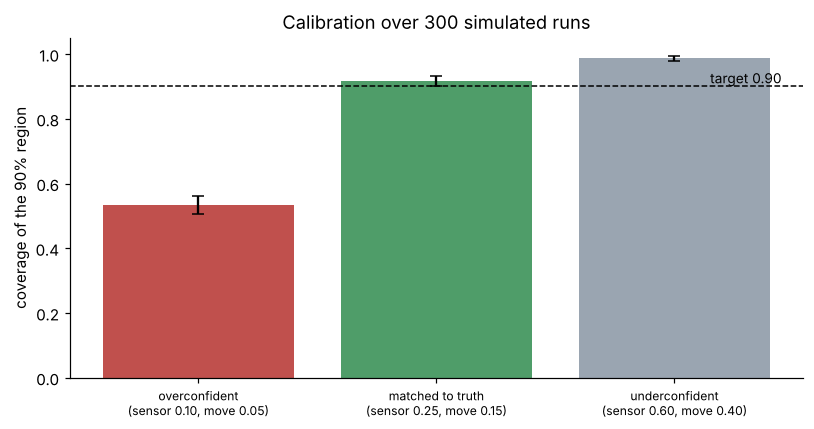

In [5]:
def credible_set(belief, level=0.9):
    # Smallest set of cells holding at least `level` of the belief, taking the most probable cells first
    order = np.argsort(belief)[::-1]
    k = int(np.searchsorted(np.cumsum(belief[order]), level)) + 1
    return order[:k]

n_runs = 300
rng = np.random.default_rng(11)
runs = [simulate_run(rng) for _ in range(n_runs)]    # the same data is used for every setting below

settings = {
    "overconfident\n(sensor 0.10, move 0.05)": (0.10, 0.05),
    "matched to truth\n(sensor 0.25, move 0.15)": (SIGMA_S_TRUE, SIGMA_M_TRUE),
    "underconfident\n(sensor 0.60, move 0.40)": (0.60, 0.40),
}

results = {}
for name, (ss, sm) in settings.items():
    hits, widths = [], []
    for x_true_run, zs_run in runs:
        b_final = run_filter(zs_run, ss, sm)[-1]
        cs = credible_set(b_final, 0.9)
        true_cell = int(round(x_true_run[-1] / dx))
        hits.append(true_cell in cs)
        widths.append(len(cs) * dx)
    p = float(np.mean(hits))
    results[name] = (p, float(np.sqrt(p * (1 - p) / n_runs)), float(np.mean(widths)))
    print("%-42s coverage %.3f +/- %.3f   mean 90%% region width %.2f m"
          % (name.replace("\n", " "), *results[name]))

fig, ax = plt.subplots(figsize=(7.5, 4))
names = list(results)
cov = [results[n][0] for n in names]
se = [results[n][1] for n in names]
ax.bar(range(3), cov, yerr=se, color=["#c0504d", "#4f9d69", "#9aa5b1"], capsize=4)
ax.axhline(0.9, color="black", ls="--", lw=1)
ax.text(2.45, 0.91, "target 0.90", ha="right", fontsize=9)
ax.set_xticks(range(3)); ax.set_xticklabels(names, fontsize=8)
ax.set_ylabel("coverage of the 90% region")
ax.set_ylim(0, 1.05)
ax.set_title("Calibration over %d simulated runs" % n_runs)
fig.tight_layout()
fig.savefig("figures/calibration.png", dpi=130)
plt.show()

Coverage was 92% (standard error 1.6 percentage points) when the filter used the true noise levels. With noise parameters that were too small, coverage fell to 53% and the mean region width was 0.24 m, so the region excluded the true position in nearly half of the runs. With noise parameters that were too large, coverage was 99% and the mean width was 1.25 m, compared with 0.57 m for the matched filter.

## 5. Limitations

- The simulated noise matches the filter's assumed model, so the matched-noise result is a best case. Non-Gaussian errors, outliers, map errors and kidnapped-robot events were not tested.
- The map and the motion commands are known. The method performs localisation only.
- The number of cells grows exponentially with the state dimension. A 20 m by 20 m area at 0.1 m resolution requires 40,000 cells, and adding heading increases this further. Particle filters and Kalman filters are used for larger problems.
- Calibration was evaluated at the final step only, over 300 runs.

Possible extensions are a particle filter evaluated with the same experiments, and evaluation on real range logs.